In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df= pd.read_csv('indian-national-level-election.csv')
df.head(10)

,st_name,year,pc_no,pc_name,pc_type,cand_name,cand_sex,partyname,partyabbre,totvotpoll,electors
0,Andaman & Nicobar Islands,1977,1,Andaman & Nicobar Islands,GEN,K.R. Ganesh,M,Independents,IND,25168,85308
1,Andaman & Nicobar Islands,1977,1,Andaman & Nicobar Islands,GEN,Manoranjan Bhakta,M,Indian National Congress,INC,35400,85308
2,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Ramesh Mazumdar,M,Independents,IND,109,96084
3,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Alagiri Swamy,M,Independents,IND,125,96084
4,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Kannu Chemy,M,Independents,IND,405,96084
5,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,K.N. Raju,M,Independents,IND,470,96084
6,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Rajender Lall Saha,M,Janta Party (Secular),JNP(S),717,96084
7,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Karpu Swamy,M,Independents,IND,1123,96084
8,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,Samar Choudhury,M,Janta Party,JNP,2034,96084
9,Andaman & Nicobar Islands,1980,1,Andaman & Nicobar Islands,GEN,K. Kanda Swamy,M,Independents,IND,15856,96084


In [3]:
print("No.of rows & columns is: ",df.shape, "\n")
print("Below is info of political data\n")
df.info(),
print("\nstatitics of political data \n")
df.describe()


No.of rows & columns is:  (73081, 11) 

Below is info of political data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73081 entries, 0 to 73080
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   st_name     73081 non-null  object
 1   year        73081 non-null  int64 
 2   pc_no       73081 non-null  int64 
 3   pc_name     73081 non-null  object
 4   pc_type     65011 non-null  object
 5   cand_name   73081 non-null  object
 6   cand_sex    72539 non-null  object
 7   partyname   73081 non-null  object
 8   partyabbre  73081 non-null  object
 9   totvotpoll  73081 non-null  int64 
 10  electors    73081 non-null  int64 
dtypes: int64(4), object(7)
memory usage: 6.1+ MB

statitics of political data 



,year,pc_no,totvotpoll,electors
count,73081.000000,73081.000000,73081.000000,7.308100e+04
mean,1996.779505,22.311490,49834.760266,1.122277e+06
std,10.432527,19.039793,104893.319706,3.560049e+05
min,1977.000000,1.000000,0.000000,1.947100e+04
25%,1989.000000,7.000000,872.000000,9.129850e+05
50%,1996.000000,18.000000,2743.000000,1.099503e+06
75%,2004.000000,33.000000,19185.000000,1.329086e+06
max,2014.000000,85.000000,863358.000000,3.368399e+06


In [4]:
# Duplicates of data
print("no of rows:", len(df))
print("No of duplicate rows :\n")
print(df.duplicated().sum())

df.drop_duplicates()
print("after removing duplicates", len(df))

no of rows: 73081
No of duplicate rows :

1
after removing duplicates 73081


In [5]:
# Missing values
missing_data = pd.DataFrame({'columns': df.columns, 
                            'missing_count': df.isnull().sum(),
                            'missing_persent': df.isnull().sum()*100/len(df)})
missing_data = missing_data[missing_data['missing_count']>0].sort_values('missing_count', ascending=False)
missing_data

,columns,missing_count,missing_persent
pc_type,pc_type,8070,11.042542
cand_sex,cand_sex,542,0.741643


In [6]:
df= df.drop(columns= ['partyabbre', 'pc_no','pc_type'])
print("rows & columns after dropping unnecessary columns\n", df.shape)

rows & columns after dropping unnecessary columns
 (73081, 8)


In [7]:
# Filling null values of cand_sex with unknown
df= df.fillna('Unknown')
print(df['cand_sex'].nunique())
print(df['cand_sex'].unique())


4
['M' 'F' 'Unknown' 'O']


In [8]:
print( df.groupby('partyname')['totvotpoll'].agg(['sum', 'count', 'mean']))


                                           sum  count          mean
partyname                                                          
A S P                                      557      1    557.000000
A-Chik National Congress(Democratic)     40204      1  40204.000000
AAAP                                  11325387    432  26216.173611
AAMJP                                     9371      1   9371.000000
AAP                                       4380      2   2190.000000
...                                        ...    ...           ...
rdsc                                     10800      2   5400.000000
shsap                                     2982      1   2982.000000
skd                                      20910      5   4182.000000
sps                                       4870      2   2435.000000
ssrd                                      7115      4   1778.750000

[1424 rows x 3 columns]


In [9]:
numerical_colms = df.select_dtypes(include=['int','float']).columns.tolist()
categorical_colms = df.select_dtypes(include=['object']).columns.tolist()
print("Numerical data:", numerical_colms)
print("categorical data: ", categorical_colms)

Numerical data: ['year', 'totvotpoll', 'electors']
categorical data:  ['st_name', 'pc_name', 'cand_name', 'cand_sex', 'partyname']


In [10]:
numerical_colms = ['totvotpoll', 'electors']

for col in numerical_colms:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR= Q3-Q1
    
    Lower_bound = Q1-1.5 *IQR
    Upper_bound = Q3+1.5 *IQR

    Outliers = df[(df[col]< Lower_bound) | (df[col]> Upper_bound)]

    print(f"\n Q1:{Q1:.2f}, Q3:{Q3:.2f}, IQR: {IQR:.2f}")
    print(f"Bounds are:{Lower_bound, Upper_bound}")
    print(f"Outliers found: {len(Outliers)},\n Percent of outliers {len(Outliers)*100/len(df)}")
    if len(Outliers)>0:
        print(f"Max outlier value:, {Outliers[col].max():.2f}")


 Q1:872.00, Q3:19185.00, IQR: 18313.00
Bounds are:(np.float64(-26597.5), np.float64(46654.5))
Outliers found: 15307,
 Percent of outliers 20.94525252801686
Max outlier value:, 863358.00

 Q1:912985.00, Q3:1329086.00, IQR: 416101.00
Bounds are:(np.float64(288833.5), np.float64(1953237.5))
Outliers found: 1520,
 Percent of outliers 2.0798839643683036
Max outlier value:, 3368399.00


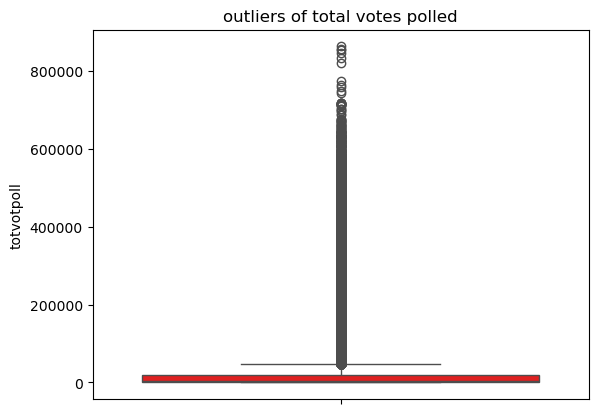

In [11]:
# Boxplot for outliers analysis

sns.boxplot(df["totvotpoll"], color= "red")
plt.title("outliers of total votes polled")
plt.show()

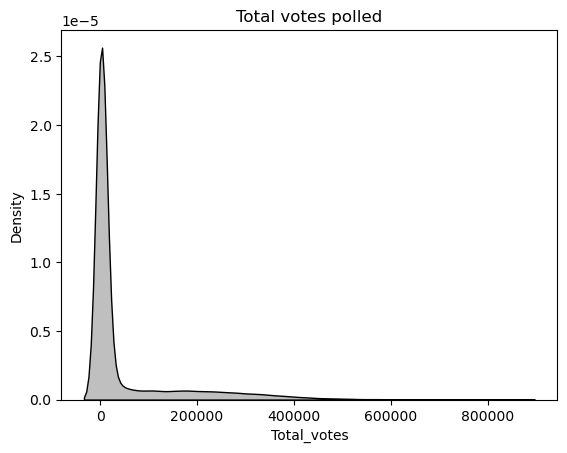

In [12]:
# Univariate analysis

sns.kdeplot(df['totvotpoll'], fill=True, color='black')
plt.title('Total votes polled')
plt.xlabel('Total_votes')
plt.show()

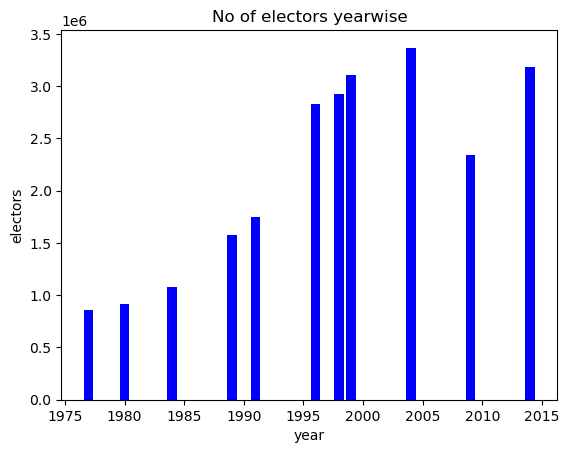

In [26]:
# Bivariate analysis

import matplotlib.pyplot as plt
plt.bar(df['year'],df['electors'], color='blue')
plt.title("No of electors yearwise")
plt.xlabel("year")
plt.ylabel('electors')
plt.show()

In [8]:
print(df[['year','totvotpoll','electors']].head())

   year  totvotpoll  electors
0  1977       25168     85308
1  1977       35400     85308
2  1980         109     96084
3  1980         125     96084
4  1980         405     96084


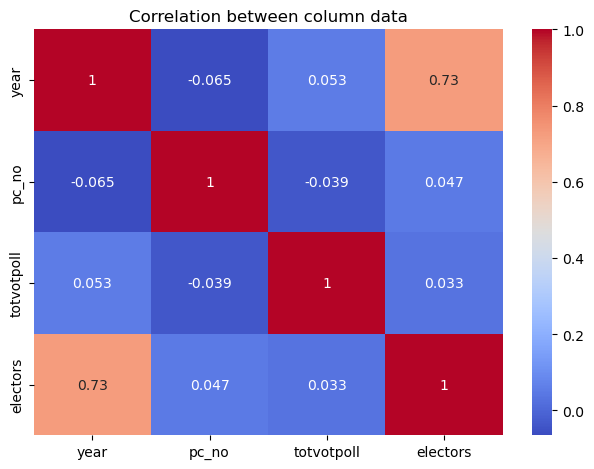

In [6]:
# correlation between columns 

correlation= df.corr(numeric_only=True)
sns.heatmap(correlation, annot =True, cmap='coolwarm')
plt.title("Correlation between column data")
plt.tight_layout()
plt.show()

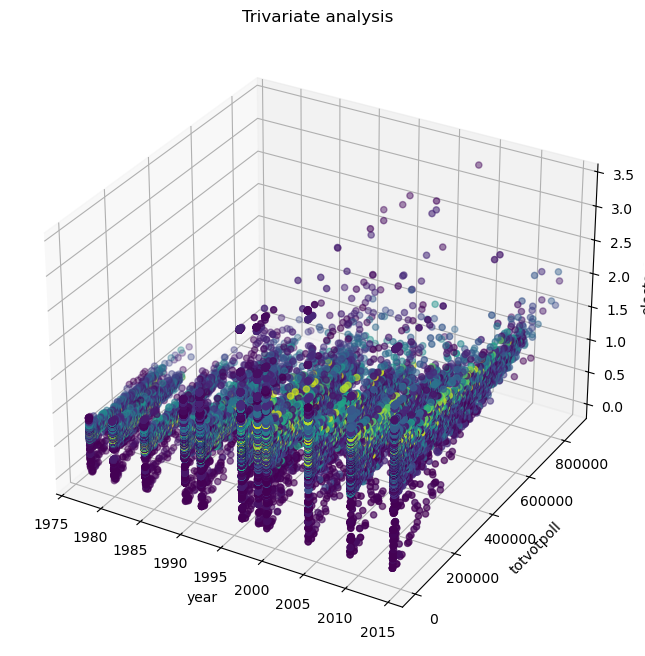

In [27]:
# multivariant 3D analsis

fig = plt.figure(figsize=(10,8))
ax= fig.add_subplot(111, projection= '3d')

ax.scatter(df['year'], df['totvotpoll'], df['electors'], c= df['pc_no'], cmap='viridis')
ax.set_xlabel('year')
ax.set_ylabel('totvotpoll')
ax.set_zlabel('electors')
plt.title("Trivariate analysis")
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>



In [28]:
# Multivariate analysis

sns.pairplot(df, hue='partyname', palette = 'colorblind')
plt.title("Multivariate analysis with pairplot")
plt.show